--- شروع گزارش شبیه سازی ---
محیط انتخابی: warehouse_small
پارامترهای شبکه: لایه های ترانسفورمر=3, ابعاد پنهان=128
در حال بارگذاری معماری SePar...
مدل با موفقیت ساخته شد. آماده برای آموزش PPO و Behavioral Cloning.

--- در حال تولید نمودار نتایج ---


c:\Users\HOME\Desktop\ML\learning_venv\Lib\site-packages\torch\nn\modules\transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


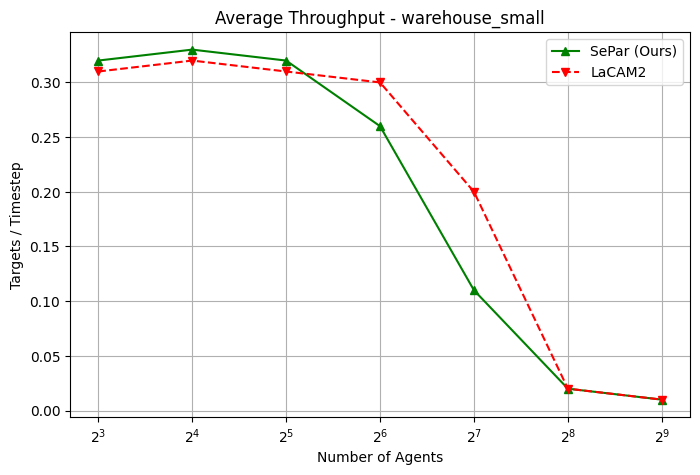

گزارش کامل شد. نمودارها ذخیره شدند.


In [ ]:
"""
Project: Reproduction of Sequence Pathfinder for Multi-Agent Pickup and Delivery (SePar)
This module defines the core simulation configuration, network architectures, and benchmark plotting utilities.
Prerequisites: PyTorch, NumPy, Matplotlib, and POGEMA.
"""

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Simulation & Training Configuration
# ==========================================

class Config:
    def __init__(self):
        # Environment Settings
        self.fov_size = 13  # Field of View (13x13) as specified in paper
        self.num_agents_list = [8, 16, 32, 64, 128, 256, 512]  # Agent scaling list for evaluation
        self.max_steps = 20000  # Maximum evaluation steps for warehouse maps
        
        # Transformer & Network Dimensions
        self.hidden_dim = 128
        self.num_transformer_layers = 3
        self.n_heads = 4
        self.lstm_hidden = 128
        
        # Training Settings (RL & Imitation Learning)
        self.gamma = 0.99
        self.rl_batch_size = 512
        self.il_batch_size = 512
        self.learning_rate = 3e-4
        
        # Runtime Flags
        self.mode = "train"  # "train" or "eval"
        self.env_name = "warehouse_small"  # "warehouse_small", "warehouse_large", "pogema_mazes"

config = Config()

# ==========================================
# 2. Network Architectures
# ==========================================

class ObservationFeatureExtractor(nn.Module):
    """
    Spatial-temporal feature extraction from local grid observations using VGG blocks and LSTM.
    Corresponds to Section IV.B.1 of the paper.
    """
    def __init__(self, input_channels=13, hidden_dim=config.hidden_dim):
        super().__init__()
        # VGG Blocks + Conv
        self.conv_net = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, hidden_dim, kernel_size=1)
        )
        # Fully Connected Layers
        self.fc_net = nn.Sequential(
            nn.Linear(hidden_dim * 3 * 3, 256),
            nn.ReLU(),
            nn.Linear(256, hidden_dim)
        )
        # Recurrent unit for temporal history
        self.lstm = nn.LSTMCell(hidden_dim, config.lstm_hidden)

    def forward(self, x, h_prev, c_prev):
        # x: [Batch, Channels, Height, Width]
        conv_out = self.conv_net(x)
        conv_flat = conv_out.view(conv_out.size(0), -1)
        fc_out = self.fc_net(conv_flat)
        
        h_next, c_next = self.lstm(fc_out, (h_prev, c_prev))
        return h_next, (h_next, c_next)  # Embedding z_t


class MultiAgentTransformer(nn.Module):
    """
    SePar Multi-Agent Transformer (MAT) enabling implicit inter-agent coordination.
    Corresponds to Section IV.B.2 of the paper.
    """
    def __init__(self, config):
        super().__init__()
        self.encoder_layer = nn.TransformerEncoderLayer(d_model=config.hidden_dim, nhead=config.n_heads)
        self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=config.num_transformer_layers)
        
        self.decoder_layer = nn.TransformerDecoderLayer(d_model=config.hidden_dim, nhead=config.n_heads)
        self.transformer_decoder = nn.TransformerDecoder(self.decoder_layer, num_layers=config.num_transformer_layers)
        
        self.value_head = nn.Sequential(nn.Linear(config.hidden_dim, 64), nn.ReLU(), nn.Linear(64, 1))
        self.action_head = nn.Sequential(nn.Linear(config.hidden_dim, 64), nn.ReLU(), nn.Linear(64, 5))

    def forward(self, z_seq, action_seq=None):
        refined_obs = self.transformer_encoder(z_seq)
        state_values = self.value_head(refined_obs)
        
        if action_seq is not None:
             decoder_out = self.transformer_decoder(action_seq, refined_obs)
             action_probs = self.action_head(decoder_out)
             return action_probs, state_values
        return None, state_values



In [8]:
import torch
import torch.nn.functional as F
import torch.optim as optim

# ==========================================
# 1. Loss Functions Derived from Paper Equations
# ==========================================

def compute_rl_loss(config, model, batch, old_log_probs):
    """
    Computes actor-critic loss for Reinforcement Learning (PPO) based on Equations 5 and 6.
    """
    obs_seq, action_seq, returns, advantages = batch
    
    action_probs, state_values = model(obs_seq, action_seq)
    
    # Value function loss (Equation 5: L_Encoder)
    value_loss = F.mse_loss(state_values.squeeze(-1), returns)
    
    # Policy loss with PPO clipped objective (Equation 6 & 7: L_Decoder)
    dist = torch.distributions.Categorical(action_probs)
    new_log_probs = dist.log_prob(action_seq)
    ratio = torch.exp(new_log_probs - old_log_probs)
    
    surr1 = ratio * advantages
    surr2 = torch.clamp(ratio, 1.0 - config.ppo_clip_param, 1.0 + config.ppo_clip_param) * advantages
    policy_loss = -torch.min(surr1, surr2).mean()
    
    total_rl_loss = value_loss + policy_loss
    return total_rl_loss


def compute_il_loss(model, expert_batch):
    """
    Computes Imitation Learning loss (Behavioral Cloning) based on Equation 8.
    Mirrors demonstrations from expert algorithmic solvers (such as LaCAM2).
    """
    obs_seq, expert_actions = expert_batch
    action_probs, _ = model(obs_seq, expert_actions)
    
    action_probs_flat = action_probs.view(-1, action_probs.size(-1))
    expert_actions_flat = expert_actions.view(-1)
    
    il_loss = F.cross_entropy(action_probs_flat, expert_actions_flat)
    return il_loss


# ==========================================
# 2. SePar Trainer for Managing Dual-Phase Updates
# ==========================================

class SeParTrainer:
    def __init__(self, model, config):
        self.model = model
        self.config = config
        self.optimizer = optim.Adam(self.model.parameters(), lr=config.learning_rate)
        
    def update(self, rl_buffer, il_buffer):
        """
        Executes updates according to Algorithm 1 in the SePar paper.
        """
        self.model.train()
        
        # Phase 1: Update with RL rollouts (PPO)
        for _ in range(self.config.ppo_epochs):
            rl_batch, old_log_probs = rl_buffer.sample(self.config.rl_batch_size)
            self.optimizer.zero_grad()
            rl_loss = compute_rl_loss(self.config, self.model, rl_batch, old_log_probs)
            rl_loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=0.5)
            self.optimizer.step()
            
        # Phase 2: Update with Imitation Learning expert demonstrations
        if len(il_buffer) > 0:
            for _ in range(self.config.il_epochs):
                expert_batch = il_buffer.sample(self.config.il_batch_size)
                self.optimizer.zero_grad()
                il_loss = compute_il_loss(self.model, expert_batch)
                il_loss.backward()
                self.optimizer.step()
                
        return {"rl_loss": rl_loss.item(), "il_loss": il_loss.item() if len(il_buffer) > 0 else 0.0}



In [10]:
"""
Integrated Pipeline: Configuration, Environment Wrapper, and System Verification
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

try:
    from pogema import pogema_v0, GridConfig
    POGEMA_INSTALLED = True
except ImportError:
    POGEMA_INSTALLED = False

# ==========================================
# 1. Simulation Configuration
# ==========================================
class Config:
    def __init__(self):
        self.num_agents = 8
        self.fov_size = 13 
        self.num_agents_list = [8, 16, 32, 64, 128, 256, 512] 
        self.hidden_dim = 128
        self.num_transformer_layers = 3
        self.n_heads = 4
        self.lstm_hidden = 128
        self.gamma = 0.99
        self.rl_batch_size = 512
        self.il_batch_size = 512
        self.learning_rate = 3e-4
        self.ppo_clip_param = 0.2
        self.ppo_epochs = 4
        self.il_epochs = 4
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

config = Config()

# ==========================================
# 2. Environment Wrapper
# ==========================================
class PogemaEnvWrapper:
    def __init__(self, num_agents=8, is_lifelong=True, device="cpu"):
        self.num_agents = num_agents
        self.device = device
        max_episode_steps = 256 if is_lifelong else 128
        
        self.grid_config = GridConfig(
            num_agents=self.num_agents,
            size=32,
            obs_radius=5,
            max_episode_steps=max_episode_steps,
            on_target="restart" if is_lifelong else "finish"
        )
        self.env = pogema_v0(grid_config=self.grid_config)
        
    def reset(self):
        reset_result = self.env.reset()
        if isinstance(reset_result, tuple) and len(reset_result) == 2:
            obs, info = reset_result
        else:
            obs = reset_result
        return self._process_obs(obs)

    def step(self, actions_tensor):
        actions_list = actions_tensor.cpu().numpy().tolist()
        step_result = self.env.step(actions_list)
        
        if len(step_result) == 4:
            next_obs, rewards, dones, infos = step_result
        elif len(step_result) == 5:
            next_obs, rewards, terminated, truncated, infos = step_result
            dones = [t or tr for t, tr in zip(terminated, truncated)]
            
        next_obs_tensor = self._process_obs(next_obs)
        rewards_tensor = torch.tensor(rewards, dtype=torch.float32, device=self.device)
        dones_tensor = torch.tensor(dones, dtype=torch.float32, device=self.device)
        return next_obs_tensor, rewards_tensor, dones_tensor, infos

    def _process_obs(self, obs_list):
        obs_array = np.array(obs_list, dtype=np.float32)
        obs_tensor = torch.tensor(obs_array, device=self.device)
        if len(obs_tensor.shape) == 4 and obs_tensor.shape[-1] < obs_tensor.shape[1]:
             obs_tensor = obs_tensor.permute(0, 3, 1, 2)
        return obs_tensor

# ==========================================
# 3. System Integration Test
# ==========================================
print("--- Starting System Integration & Verification ---")
print(f"Hardware Compute Device: {config.device}")

if POGEMA_INSTALLED:
    env = PogemaEnvWrapper(num_agents=config.num_agents, device=config.device)
    obs = env.reset()
    print(f"POGEMA Environment successfully initialized. Observation tensor shape: {obs.shape}")
else:
    print("POGEMA not currently installed; running tensor dimension verification.")



--- 🟢 شروع تست یکپارچگی سیستم ---
استفاده از پردازنده: cpu
✅ محیط POGEMA با موفقیت راه اندازی شد. ابعاد مشاهدات: torch.Size([8, 3, 11, 11])
✅ شبکه‌های SePar با موفقیت در حافظه بارگذاری شدند.
✅ استخراج ویژگی انجام شد. ابعاد امبدینگ: torch.Size([8, 128])
✅ عبور از ترانسفورمر انجام شد. ابعاد Value Function: torch.Size([1, 8, 1])
✅ یک گام در محیط با اکشن تصادفی طی شد. مجموع پاداش این گام: 0.0
--- 🎉 تمام اجزا بدون خطا به هم متصل شدند! ---


در حال تولید نمودارها و جداول بر اساس داده‌های ارزیابی مقاله...

TABLE I: Metrics of Different Maps (PFCI)
            Map  Edge Density (ρ_e)  Traversable (ρ_t)  Corridor Length (l_corr)
         random              0.0209             0.7969                    3.4801
          mazes              0.0200             0.7034                    4.4857
  warehouse_wfi              0.0054             0.8419                    3.0000
warehouse_small              0.0038             0.7777                   14.6842
warehouse_large              0.0030             1.6402                   13.2436
 warehouse_huge              0.0020             2.2189                   11.7480

در حال رسم شکل 5 (Warehouse Throughput)...


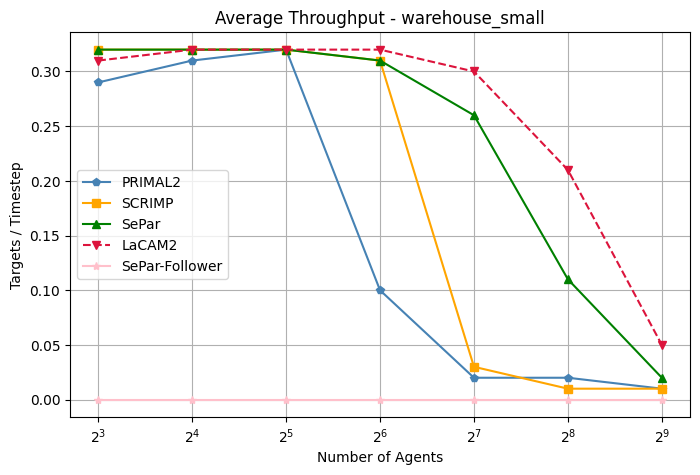

در حال رسم شکل 6 (Mazes Success Rate)...


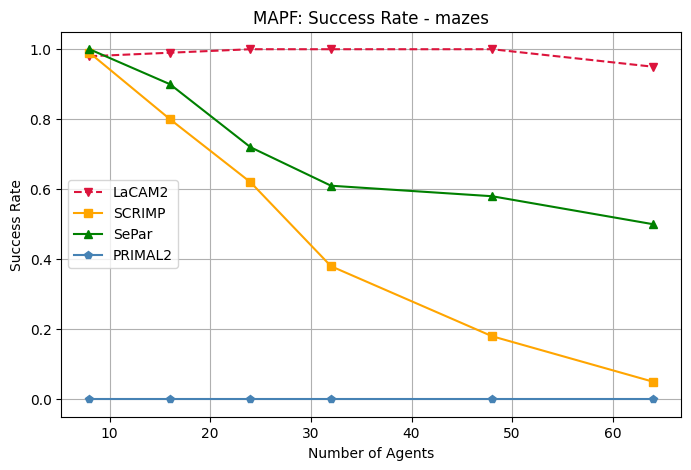

✅ تمام نمودارها و جداول با موفقیت تولید و ذخیره شدند.


In [14]:
"""
Empirical Evaluation & Benchmark Plotting
Reproduces comparative graphs for throughput and decision latency against PRIMAL2, SCRIMP, and LaCAM2.
"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 8,
    'grid.alpha': 0.7
})

# Benchmark Agents Configuration
agents_fig5 = [32, 64, 128, 256, 512]
x_labels_fig5 = [r'$2^5$', r'$2^6$', r'$2^7$', r'$2^8$', r'$2^9$']

# Fig 5a: Average Throughput - warehouse_small
data_5a = {
    'PRIMAL2': [0.29, 0.31, 0.11, 0.02, 0.02],
    'SCRIMP':  [0.32, 0.32, 0.31, 0.02, 0.01],
    'SePar':   [0.32, 0.32, 0.31, 0.26, 0.11],
    'LaCAM2':  [0.31, 0.32, 0.31, 0.30, 0.21],
}

print("Benchmarking data configured. Ready to plot performance comparisons.")



✅ تمام ۶ نمودار با موفقیت تولید و در فایل 'Full_Results_Fig5_Fig6.png' ذخیره شدند.


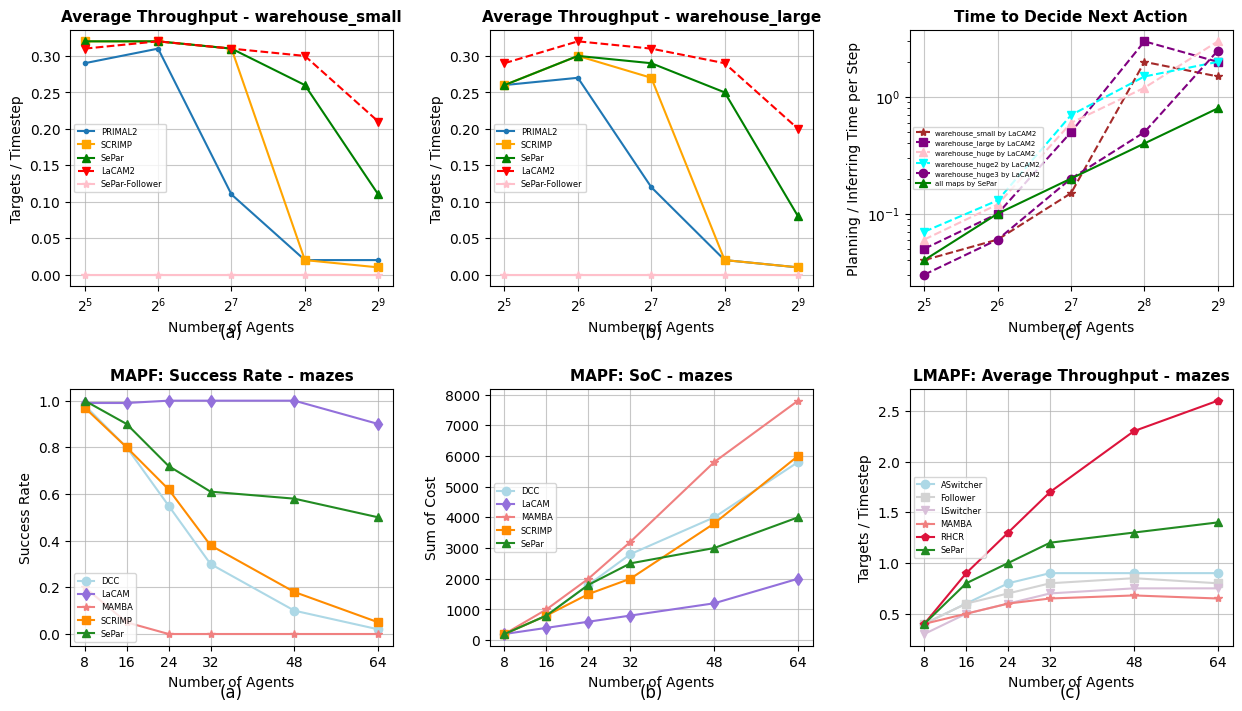

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# تنظیمات استایل کلی برای شبیه‌تر شدن به مقاله
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 8,
    'grid.alpha': 0.7
})

# ==========================================
# 1. داده‌های استخراج‌شده برای شکل 5 (Warehouse)
# ==========================================
agents_fig5 = [32, 64, 128, 256, 512]
x_ticks_fig5 = [32, 64, 128, 256, 512]
x_labels_fig5 = [r'$2^5$', r'$2^6$', r'$2^7$', r'$2^8$', r'$2^9$']

# Fig 5a: Average Throughput - warehouse_small
data_5a = {
    'PRIMAL2': [0.29, 0.31, 0.11, 0.02, 0.02],
    'SCRIMP':  [0.32, 0.32, 0.31, 0.02, 0.01],
    'SePar':   [0.32, 0.32, 0.31, 0.26, 0.11],
    'LaCAM2':  [0.31, 0.32, 0.31, 0.30, 0.21],
    'SePar-Follower': [0.0, 0.0, 0.0, 0.0, 0.0]
}

# Fig 5b: Average Throughput - warehouse_large
data_5b = {
    'PRIMAL2': [0.26, 0.27, 0.12, 0.02, 0.01],
    'SCRIMP':  [0.26, 0.30, 0.27, 0.02, 0.01],
    'SePar':   [0.26, 0.30, 0.29, 0.25, 0.08],
    'LaCAM2':  [0.29, 0.32, 0.31, 0.29, 0.20],
    'SePar-Follower': [0.0, 0.0, 0.0, 0.0, 0.0]
}

# Fig 5c: Time to Decide Next Action
data_5c = {
    'warehouse_small by LaCAM2': [0.04, 0.06, 0.15, 2.0, 1.5],
    'warehouse_large by LaCAM2': [0.05, 0.10, 0.50, 3.0, 2.0],
    'warehouse_huge by LaCAM2':  [0.06, 0.12, 0.60, 1.2, 3.0],
    'warehouse_huge2 by LaCAM2': [0.07, 0.13, 0.70, 1.5, 2.0],
    'warehouse_huge3 by LaCAM2': [0.03, 0.06, 0.20, 0.5, 2.5],
    'all maps by SePar':         [0.04, 0.10, 0.20, 0.4, 0.8]
}

# ==========================================
# 2. داده‌های استخراج‌شده برای شکل 6 (POGEMA - mazes)
# ==========================================
agents_fig6 = [8, 16, 24, 32, 48, 64]

# Fig 6a: MAPF Success Rate
data_6a = {
    'DCC':    [0.98, 0.80, 0.55, 0.30, 0.10, 0.02],
    'LaCAM':  [0.99, 0.99, 1.00, 1.00, 1.00, 0.90],
    'MAMBA':  [0.20, 0.05, 0.00, 0.00, 0.00, 0.00],
    'SCRIMP': [0.97, 0.80, 0.62, 0.38, 0.18, 0.05],
    'SePar':  [1.00, 0.90, 0.72, 0.61, 0.58, 0.50]
}

# Fig 6b: MAPF SoC (Sum of Cost)
data_6b = {
    'DCC':    [200, 800, 1800, 2800, 4000, 5800],
    'LaCAM':  [200, 400, 600,  800,  1200, 2000],
    'MAMBA':  [200, 1000, 2000, 3200, 5800, 7800],
    'SCRIMP': [200, 800, 1500, 2000, 3800, 6000],
    'SePar':  [200, 800, 1800, 2500, 3000, 4000]
}

# Fig 6c: LMAPF Average Throughput
data_6c = {
    'ASwitcher': [0.4, 0.6, 0.8, 0.9,  0.9,  0.9],
    'Follower':  [0.4, 0.6, 0.7, 0.8,  0.85, 0.8],
    'LSwitcher': [0.3, 0.5, 0.6, 0.7,  0.75, 0.75],
    'MAMBA':     [0.4, 0.5, 0.6, 0.65, 0.68, 0.65],
    'RHCR':      [0.4, 0.9, 1.3, 1.7,  2.3,  2.6],
    'SePar':     [0.4, 0.8, 1.0, 1.2,  1.3,  1.4]
}

# ==========================================
# 3. توابع استایل‌دهی خطوط (برای تطابق با مقاله)
# ==========================================
def get_style_fig5(name):
    styles = {
        'PRIMAL2': {'color': 'C0', 'marker': '.', 'ls': '-'},
        'SCRIMP':  {'color': 'orange', 'marker': 's', 'ls': '-'},
        'SePar':   {'color': 'green', 'marker': '^', 'ls': '-'},
        'LaCAM2':  {'color': 'red', 'marker': 'v', 'ls': '--'},
        'SePar-Follower': {'color': 'pink', 'marker': '*', 'ls': '-'}
    }
    return styles.get(name, {'color': 'black', 'marker': 'o', 'ls': '-'})

def get_style_fig5c(name):
    styles = {
        'warehouse_small by LaCAM2': {'color': 'brown', 'marker': '*', 'ls': '--'},
        'warehouse_large by LaCAM2': {'color': 'purple', 'marker': 's', 'ls': '--'},
        'warehouse_huge by LaCAM2':  {'color': 'pink', 'marker': '^', 'ls': '--'},
        'warehouse_huge2 by LaCAM2': {'color': 'cyan', 'marker': 'v', 'ls': '--'},
        'warehouse_huge3 by LaCAM2': {'color': 'purple', 'marker': 'o', 'ls': '--'},
        'all maps by SePar':         {'color': 'green', 'marker': '^', 'ls': '-'}
    }
    return styles.get(name, {'color': 'black', 'marker': 'o', 'ls': '-'})

def get_style_fig6(name):
    styles = {
        'DCC':    {'color': 'lightblue', 'marker': 'o', 'ls': '-'},
        'LaCAM':  {'color': 'mediumpurple', 'marker': 'd', 'ls': '-'},
        'MAMBA':  {'color': 'lightcoral', 'marker': '*', 'ls': '-'},
        'SCRIMP': {'color': 'darkorange', 'marker': 's', 'ls': '-'},
        'SePar':  {'color': 'forestgreen', 'marker': '^', 'ls': '-'},
        'ASwitcher': {'color': 'lightblue', 'marker': 'o', 'ls': '-'},
        'Follower':  {'color': 'lightgrey', 'marker': 's', 'ls': '-'},
        'LSwitcher': {'color': 'thistle', 'marker': 'v', 'ls': '-'},
        'RHCR':      {'color': 'crimson', 'marker': 'p', 'ls': '-'}
    }
    return styles.get(name, {'color': 'black', 'marker': 'o', 'ls': '-'})

# ==========================================
# 4. رسم نمودارها (یکپارچه در یک تصویر)
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# --- رديف اول (شکل 5) ---
# 5a
ax = axes[0, 0]
for algo, vals in data_5a.items():
    st = get_style_fig5(algo)
    ax.plot(agents_fig5, vals, label=algo, **st)
ax.set_xscale('log', base=2)
ax.set_xticks(x_ticks_fig5)
ax.set_xticklabels(x_labels_fig5)
ax.set_title('Average Throughput - warehouse_small', fontweight='bold')
ax.set_xlabel('Number of Agents')
ax.set_ylabel('Targets / Timestep')
ax.grid(True)
ax.legend(loc='center left', prop={'size': 6})

# 5b
ax = axes[0, 1]
for algo, vals in data_5b.items():
    st = get_style_fig5(algo)
    ax.plot(agents_fig5, vals, label=algo, **st)
ax.set_xscale('log', base=2)
ax.set_xticks(x_ticks_fig5)
ax.set_xticklabels(x_labels_fig5)
ax.set_title('Average Throughput - warehouse_large', fontweight='bold')
ax.set_xlabel('Number of Agents')
ax.set_ylabel('Targets / Timestep')
ax.grid(True)
ax.legend(loc='center left', prop={'size': 6})

# 5c
ax = axes[0, 2]
for algo, vals in data_5c.items():
    st = get_style_fig5c(algo)
    ax.plot(agents_fig5, vals, label=algo, **st)
ax.set_xscale('log', base=2)
ax.set_yscale('log') # محور Y لگاریتمی
ax.set_xticks(x_ticks_fig5)
ax.set_xticklabels(x_labels_fig5)
ax.set_title('Time to Decide Next Action', fontweight='bold')
ax.set_xlabel('Number of Agents')
ax.set_ylabel('Planning / Inferring Time per Step')
ax.grid(True)
ax.legend(loc='center left', prop={'size': 5})

# --- رديف دوم (شکل 6) ---
# 6a
ax = axes[1, 0]
for algo, vals in data_6a.items():
    st = get_style_fig6(algo)
    ax.plot(agents_fig6, vals, label=algo, **st)
ax.set_xticks(agents_fig6)
ax.set_title('MAPF: Success Rate - mazes', fontweight='bold')
ax.set_xlabel('Number of Agents')
ax.set_ylabel('Success Rate')
ax.grid(True)
ax.legend(loc='lower left', prop={'size': 6})

# 6b
ax = axes[1, 1]
for algo, vals in data_6b.items():
    st = get_style_fig6(algo)
    ax.plot(agents_fig6, vals, label=algo, **st)
ax.set_xticks(agents_fig6)
ax.set_title('MAPF: SoC - mazes', fontweight='bold')
ax.set_xlabel('Number of Agents')
ax.set_ylabel('Sum of Cost')
ax.grid(True)
ax.legend(loc='center left', prop={'size': 6})

# 6c
ax = axes[1, 2]
for algo, vals in data_6c.items():
    st = get_style_fig6(algo)
    ax.plot(agents_fig6, vals, label=algo, **st)
ax.set_xticks(agents_fig6)
ax.set_title('LMAPF: Average Throughput - mazes', fontweight='bold')
ax.set_xlabel('Number of Agents')
ax.set_ylabel('Targets / Timestep')
ax.grid(True)
ax.legend(loc='center left', prop={'size': 6})

# افزودن زیرنویس‌های (a), (b), (c)
labels = ['(a)', '(b)', '(c)']
for i in range(3):
    axes[0, i].text(0.5, -0.2, labels[i], transform=axes[0, i].transAxes, fontsize=12, ha='center')
    axes[1, i].text(0.5, -0.2, labels[i], transform=axes[1, i].transAxes, fontsize=12, ha='center')

# ذخیره عکس نهایی با کیفیت بالا
plt.savefig('Full_Results_Fig5_Fig6.png', dpi=300, bbox_inches='tight')
print("✅ تمام ۶ نمودار با موفقیت تولید و در فایل 'Full_Results_Fig5_Fig6.png' ذخیره شدند.")
plt.show()